# 5. 节点执行与容错机制
节点执行失败时，如果未做任何处理，可能导致整个运行图执行失败。为了提升运行图的稳定性，处理临时故障、超时、异常恢复以及重复计算等问题，**`LangGraph`** 提供了一系列节点执行与容错机制：重试、超时设置、异常处理和节点缓存。


这些错误问题与机制的对应关系如下:

| 问题/场景    | 对应机制                    | 机制类型             | 说明                                                         |
| ------------ | --------------------------- | -------------------- | ------------------------------------------------------------ |
| **临时故障** | **重试 Retry**              | **节点容错机制**     | 网络抖动、接口偶发失败、模型服务短暂不可用，可以通过重试机制再次执行节点。 |
| **超时**     | **超时设置 Timeout**        | **节点容错机制**     | 某个节点执行时间过长，可以通过超时限制避免图运行被长时间阻塞。 |
| **异常恢复** | **异常处理 Error Handling** | **节点容错机制**     | 节点抛出异常后，通过异常捕获、兜底逻辑、降级返回、路由到错误处理节点等方式恢复流程。 |
| **重复计算** | **缓存 Cache**              | **节点执行优化机制** | 相同输入反复触发耗时节点，可以通过节点缓存避免重复执行，提高性能。 |

## 5.1 Langgraph的节点容错机制
**`LangGraph`** 提供了三种异常处理机制

- **`retries`**：重试机制。节点执行失败时，根据重试策略自动重新执行。
- **`Timeouts`**：超时控制。限制单次节点执行的最大等待时间。
- **`Error Handling`**：错误处理。重试次数耗尽后，执行特定的异常处理逻辑。

当超时或者执行错误抛出异常，根据重试策略 **`RetryPolicy`** 判断该异常是否需要重试。重试次数耗尽后，执行特定的异常处理逻辑。

## 5.2 重试机制
重试机制用于处理临时性异常，例如网络抖动、远程服务短暂不可用、API 偶发失败等。

在添加节点时，可以通过 **`retry_policy=`** 配置节点的重试策略。

2026-10-16 00:23:28.660 | INFO     | __main__:node_a:12 - node a 运行
2026-10-16 00:23:29.166 | INFO     | __main__:node_a:12 - node a 运行
2026-10-16 00:23:30.168 | INFO     | __main__:node_a:12 - node a 运行
2026-10-16 00:23:30.176 | INFO     | __main__:<module>:32 - 重试次数耗尽: 网络连接超时...


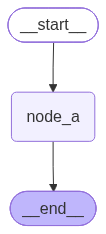

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy

from requests.exceptions import HTTPError
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState) -> EmptyState:
    logger.info(f"node a 运行")
    raise HTTPError("网络连接超时...")

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    retry_policy=RetryPolicy(
        max_attempts=3,
        jitter=False
    )
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()

try:
    graph.invoke({})
except HTTPError as e:
    logger.info("重试次数耗尽: {}", e)

from IPython.display import display
display(graph)

### 5.2.2 重试策略配置详解

超时策略通过 **`RetryPolicy`** 定义。下面是源代码。

和 [ToolRetryMiddleware](/Users/skk/Developer/lang-chain-learn/Chapter08_Middleware/06-other中间件.ipynb) 定义的中间件有点像。

* jitter 指开启抖动（在等待时间中加入随机性，防止并发请求时出现“惊群效应”）

```python
class RetryPolicy(NamedTuple):
    """Configuration for retrying nodes.

    !!! version-added "Added in version 0.2.24"
    """

    initial_interval: float = 0.5
    """Amount of time that must elapse before the first retry occurs. In seconds."""
    backoff_factor: float = 2.0
    """Multiplier by which the interval increases after each retry."""
    max_interval: float = 128.0
    """Maximum amount of time that may elapse between retries. In seconds."""
    max_attempts: int = 3
    """Maximum number of attempts to make before giving up, including the first."""
    jitter: bool = True
    """Whether to add random jitter to the interval between retries."""
    retry_on: (
        type[Exception] | Sequence[type[Exception]] | Callable[[Exception], bool]
    ) = default_retry_on
    """List of exception classes that should trigger a retry, or a callable that returns `True` for exceptions that should trigger a retry."""

```

| 参数                   | 类型                                                         | 默认值                 | 描述                                     |
| :--------------------- | :----------------------------------------------------------- | :--------------------- | :--------------------------------------- |
| **`max_attempts`**     | **`int`**                                                    | **`3`**                | 最大尝试次数（包括首次执行）             |
| **`initial_interval`** | **`float`**                                                  | **`0.5`**              | 第一次重试前的等待时间，单位：秒         |
| **`backoff_factor`**   | **`float`**                                                  | **`2.0`**              | 每次重试后等待时间的放大倍数             |
| **`max_interval`**     | **`float`**                                                  | **`128.0`**            | 相邻两次重试之间的最大等待时间，单位：秒 |
| **`jitter`**           | **`bool`**                                                   | **`True`**             | 是否为重试间隔添加随机抖动               |
| **`retry_on`**         | **`type[Exception] /Sequence[type[Exception]] / Callable[[Exception], bool]`** | **`default_retry_on`** | 哪些异常需要触发重试                     |

示例 retry_on 的自定义函数.

```python
def should_retry(exc: Exception) -> bool:
    return isinstance(exc, HTTPError)

RetryPolicy(retry_on=should_retry)
```

**`default_retry_on`** 是一个可调用对象，它接收一个 **`Exception`** 实例,会对大多数异常进行重试,除了 ValueError、TypeError等错误。

下面是核心逻辑:

```python
def default_retry_on(exc: Exception) -> bool:
    import httpx
    import requests

    if isinstance(exc, ConnectionError):
        return True
    if isinstance(exc, httpx.HTTPStatusError):
        return 500 <= exc.response.status_code < 600
    if isinstance(exc, requests.HTTPError):
        return 500 <= exc.response.status_code < 600 if exc.response else True
    if isinstance(
        exc,
        (
            ValueError,
            TypeError,
            ArithmeticError,
            ImportError,
            LookupError,
            NameError,
            SyntaxError,
            RuntimeError,
            ReferenceError,
            StopIteration,
            StopAsyncIteration,
            OSError,
        ),
    ):
        return False
    return True
```

## 5.3 超时控制

### 5.3.1 使用要求
用于 因为外部服务无响应、网络阻塞或异步任务卡住而长时间不返回 的 节点，限制单次节点执行的最大耗时

* 节点的类型要求

**节点级超时控制仅适用于异步节点，即使用 **`async def`** 定义的节点。**

同步节点一旦开始执行，通常会阻塞当前线程。**`Python`** 进程内缺少一种通用、安全的机制，可以从外部强行终止正在运行的同步函数；如果强行中断，可能导致资源未释放、锁未释放或副作用处于不一致状态。因此，**`LangGraph `** 的节点级超时更适合用于异步节点。对于同步节点，应优先在节点内部使用具体库提供的超时参数，例如 **`HTTP `** 客户端、数据库驱动或 **`SDK`** 自带的 **`timeout`** 配置。

### 5.3.2 核心思想
> 为单次节点设置超时时间，运行时长超过超时时间，节点运行失败，并抛出超时异常。

```python
# 注意：节点必须是 async def 定义的异步节点，
# 且必须使用异步执行路径（ainvoke / astream）调用
async def call_model(state: State) -> State:
    ...

builder.add_node(
    "call_model",
    call_model,
    timeout=TimeoutPolicy(run_timeout=60),
    # 空闲超时示例：
    # timeout=TimeoutPolicy(
    #     idle_timeout=30,          # 无进展时的最长空闲时间
    #     refresh_on="heartbeat",   # 仅 runtime.heartbeat() 刷新空闲计时
    # ),
)

result = await graph.ainvoke(...)
```

* 超时后会抛出 **`NodeTimeoutError`**。
* 该异常会交给 **`RetryPolicy`** 判断是否需要重试。
* 如果重试次数耗尽，才会进入错误处理逻辑。
* **节点级超时只支持异步节点与异步调用**：节点必须用 `async def` 定义，并通过 `ainvoke` / `astream` 调用；使用同步 `invoke` 会报错。


源码:

```python
TimeoutPolicy(
  self,
  *,
  run_timeout: float | timedelta | None = None,
  idle_timeout: float | timedelta | None = None,
  refresh_on: Literal['auto', 'heartbeat'] = 'auto'
)
```

| 参数               | 描述                                                         |
| :----------------- | :----------------------------------------------------------- |
| **`run_timeout`**  | 超时时间，即单次节点运行的最长时间                           |
| **`idle_timeout`** | 节点没有可观察进展（如写状态、流式输出等）时的最长空闲时间   |
| **`refresh_on`**   | 空闲时间的刷新方式，可以是手动刷新或自动刷新。默认为自动刷新，此时写状态、流式输出等都会刷新 |


* "auto"（默认）：写状态、流式输出等常规进展信号 + 显式心跳都会刷新空闲计时；
* "heartbeat"：只有 runtime.heartbeat() 调用才会刷新空闲计时。


In [ ]:
import asyncio
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import TimeoutPolicy
from langgraph.runtime import Runtime
from loguru import logger

class EmptyState(TypedDict):
    pass

async def long_running_node(state: EmptyState, runtime: Runtime) -> EmptyState:
    """一个耗时较长、但会定期汇报进展的异步节点。"""
    for i in range(4):
        await asyncio.sleep(1)      # 模拟耗时工作
        runtime.heartbeat()         # 显式汇报进展，刷新 idle_timeout
        logger.info("第 {} 轮工作完成，已发送心跳", i + 1)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "long_running_node",
    long_running_node,
    # idle_timeout=2：连续 2 秒无进展即判定为超时
    # refresh_on="heartbeat"：只有 runtime.heartbeat() 会刷新空闲计时，
    #   此时写状态、流式输出等常规进展信号不会刷新
    timeout=TimeoutPolicy(idle_timeout=2, refresh_on="heartbeat"),
)
builder.add_edge(START, "long_running_node")
builder.add_edge("long_running_node", END)

graph = builder.compile()

# 节点级超时只支持异步执行路径，必须使用 ainvoke / astream 调用
try:
    asyncio.run(graph.ainvoke({}))
    logger.info("节点正常运行结束")
except Exception as e:
    logger.info("出现错误: {}", e)

from IPython.display import display
display(graph)


## 5.4 错误处理
### 5.4.1 核心思想
错误处理机制用于在节点最终失败后，执行兜底逻辑。

在 **`add_node`** 中通过 **`error_handler=`** 设置错误处理逻辑。

例如：

```python
builder.add_node(
    "call_api",
    call_api,
    retry_policy=RetryPolicy(max_attempts=3),
    error_handler=handle_api_error
)
```

其含义是：

1. **`call_api`** 执行失败。
2. **`RetryPolicy`** 判断是否重试。
3. 最多尝试 3 次。
4. 3 次仍然失败后，调用 **`handle_api_error`**。
5. **`handle_api_error`** 可以返回状态更新，也可以通过 **`Command`** 路由到其他节点。

{'status': 'compensated: payment gateway timeout'}


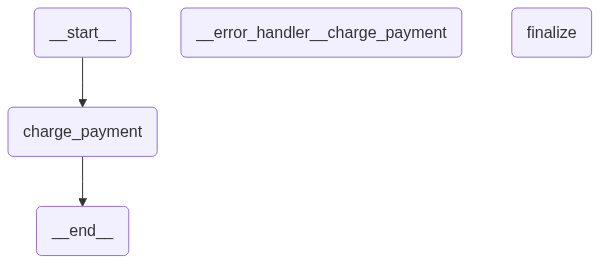

In [6]:
from langgraph.errors import NodeError
from langgraph.types import Command, RetryPolicy
from langgraph.graph import StateGraph, START
from typing_extensions import TypedDict

class State(TypedDict):
    status: str

def charge_payment(state: State) -> State:
    raise RuntimeError("payment gateway timeout")

def payment_error_handler(state: State, error: NodeError) -> Command:
    return Command(
        update={"status": f"compensated: {error.error}"},
        goto="finalize",
    )

def finalize(state: State) -> State:
    return state

graph = (
    StateGraph(State)
    .add_node(
        "charge_payment",
        charge_payment,
        retry_policy=RetryPolicy(max_attempts=3, retry_on=ConnectionError),
        error_handler=payment_error_handler,
    )
    .add_node("finalize", finalize)
    .add_edge(START, "charge_payment")
    .compile()
)

print(graph.invoke({}))

from IPython.display import display
display(graph)

上面的例子使用了 `error: NodeError` 来获取节点级别的 Failures 失败上下文

## 5.5 节点缓存
### 5.5.1 什么是节点缓存？
定义:将节点的历史运行结果保存下来，后续当节点收到相同输入时，不再重复执行节点函数，而是直接返回之前缓存的结果。

如果相同输入会多次出现，那么可以考虑启用节点缓存。


### 5.5.2 适用场景

缓存是以 **键值对** 形式存储的，每个缓存都有唯一的 **`Key`**，**缓存键函数** 用于生成唯一键。

默认情况下，**`CachePolicy`** 使用 **`default_cache_key`** 作为缓存键函数。后者基于节点输入调用 **`pickle`** 库的序列化功能生成**缓存唯一键**。

使用默认缓存键函数时，建议输入**尽量使用简单、稳定、可序列化的数据结构**，例如：

* **`str`**
* **`int`**
* **`float`**
* **`bool`**
* **`dict`**
* **`list`**
* **`tuple`**

如果节点输入中包含复杂对象、文件句柄、数据库连接、模型实例、动态对象等，建议自定义 **`key_func`**，避免缓存 **`Key`** 不稳定或无法生成。


### 5.5.3 基本用法

1. 首先配置 cache_policy

```python
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
```

2. 编译图时启用缓存后端

仅仅为节点配置 **`cache_policy`** 还不够，还需要在编译图时指定缓存后端。

```python
graph = builder.compile(cache=InMemoryCache())
```


源码部分:
1. CachePolicy
* key_func: 生成 cache key 的 function
* ttl: 过期时间,None 表示不过期,单位秒


```python
CachePolicy(
  self,
  *,
  key_func: KeyFuncT = default_cache_key,
  ttl: int | None = None
)
```

默认缓存键函数是 **`default_cache_key`**。

其核心实现如下：

```python
def default_cache_key(*args: Any, **kwargs: Any) -> str | bytes:
    """Default cache key function that uses the arguments and keyword arguments to generate a hashable key."""
    import pickle

    # protocol 5 strikes a good balance between speed and size
    return pickle.dumps((_freeze(args), _freeze(kwargs)), protocol=5, fix_imports=False)
```

它会把节点输入参数经过处理后，使用 **`pickle`** 序列化为字节序列，并将后者作为缓存 **`Key`**。




2. InMemoryCache: 声明缓存数据实际保存在哪里。

和短期记忆存储的`InMemorySaver`很相似。

2026-10-16 02:36:39.837 | INFO     | __main__:<module>:33 - 首次调用图
2026-10-16 02:36:39.839 | INFO     | __main__:node_a:15 - node_a 被调用, user: 小明
2026-10-16 02:36:42.841 | INFO     | __main__:node_a:17 - node_a 耗时操作执行完毕
2026-10-16 02:36:42.846 | INFO     | __main__:<module>:34 - 运行结果: {'user': '小明', 'invoke_counts': 1}


2026-10-16 02:36:42.846 | INFO     | __main__:<module>:35 - 相同输入再次调用图
2026-10-16 02:36:42.848 | INFO     | __main__:<module>:36 - 运行结果: {'user': '小明', 'invoke_counts': 1}


2026-10-16 02:36:42.849 | INFO     | __main__:<module>:37 - 不同输入再次调用图
2026-10-16 02:36:42.850 | INFO     | __main__:node_a:15 - node_a 被调用, user: 小花
2026-10-16 02:36:45.855 | INFO     | __main__:node_a:17 - node_a 耗时操作执行完毕
2026-10-16 02:36:45.857 | INFO     | __main__:<module>:38 - 运行结果: {'user': '小花', 'invoke_counts': 1}


2026-10-16 02:36:45.857 | INFO     | __main__:<module>:39 - 不同输入再次调用图
2026-10-16 02:36:45.858 | INFO     | __main__:node_a:15 - node_a 被调用, user: 小花
2026-10-16 02:36:48.862 | INFO

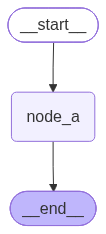

In [7]:
import time
from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.cache.memory import InMemoryCache
from langgraph.types import CachePolicy

from operator import add
from loguru import logger

class EmptyState(TypedDict):
    user: str
    invoke_counts: Annotated[int, add]

def node_a(state: EmptyState) -> EmptyState:
    logger.info("node_a 被调用, user: {}", state["user"])
    time.sleep(3) # 模拟耗时操作
    logger.info("node_a 耗时操作执行完毕")

    return {
        "invoke_counts": 1
    }

builder = StateGraph(state_schema=EmptyState)
builder.add_node(
    "node_a",
    node_a,
    cache_policy=CachePolicy(ttl=10)
)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile(cache=InMemoryCache())
logger.info("首次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("相同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小明", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 0}))
logger.info("不同输入再次调用图")
logger.info("运行结果: {}\n\n", graph.invoke({"user": "小花", "invoke_counts": 2}))
time.sleep(10) # 确保第一次调用缓存失效
logger.info("10秒后相同输入再次调用图，此时缓存已失效")
logger.info("运行结果: {}", graph.invoke({"user": "小明", "invoke_counts": 0}))

from IPython.display import display
display(graph)

## 5.6 全图默认配置
### 5.6.1 核心思想
当多个节点都需要配置相同的执行策略时，如果每个节点都重复配置，繁琐且耗时。
因此引入` set_node_defaults`配置整个图的默认参数。

### 5.6.2 使用
默认配置可以包括：

* **`retry_policy`**
* **`timeout`**
* **`error_handler`**
* **`cache_policy`**

In [16]:
from langgraph.errors import NodeError
from langgraph.types import RetryPolicy, TimeoutPolicy
from langgraph.graph import StateGraph, START
from typing_extensions import TypedDict
import asyncio
class State(TypedDict):
    status: str

async def default_error_handler(state: State, error: NodeError) -> State:
    return {"status": f"handled: {error.error}"}

async def step_a(state: State) -> State:
    return {"status": "step_a"}

async def step_b(state: State) -> State:
    return {"status": "step_b"}


graph = (
    StateGraph(State)
    .set_node_defaults(
        retry_policy=RetryPolicy(max_attempts=3),
        error_handler=default_error_handler,
        timeout=TimeoutPolicy(run_timeout=30),
    )
    .add_node("step_a", step_a)
    .add_node("step_b", step_b)
    .add_edge(START, "step_a")
    .compile()
)

print(await graph.ainvoke({}))

{'status': 'step_a'}


# 总结

### 1. NodeError：节点失败上下文

`NodeError` 是框架传给 `error_handler=` 注册函数的失败上下文，是不可变的数据对象，本身不是异常；其中的 `error` 属性才是原始异常对象。

源码定义:
```python
@dataclass(frozen=True, slots=True)
class NodeError:
    node: str
    error: BaseException
```

| 属性 | 意义 | 本节示例中的值 |
| --- | --- | --- |
| `error.node` | 失败节点的名称 | `"charge_payment"` |
| `error.error` | 节点抛出的原始异常，可用 `isinstance()` 判断类型 | `RuntimeError("payment gateway timeout")` |

示例（沿用 5.4 中的 `State` 和 `finalize` 节点）：

```python
from langgraph.errors import NodeError
from langgraph.types import Command

def payment_error_handler(state: State, error: NodeError) -> Command:
    print(f"节点 {error.node} 失败，异常类型：{type(error.error).__name__}")
    return Command(
        update={"status": f"handled: {error.error}"},
        goto="finalize",
    )
```

处理函数在节点失败且不再重试时运行：可能是重试次数耗尽，也可能是异常不符合重试条件。5.4 示例抛出 `RuntimeError`，而 `retry_on=ConnectionError`，因此首次失败就进入处理函数；若要观察三次尝试，可将抛出的异常改为 `ConnectionError`。

### 2. 节点常用的注入参数

除了第一个状态参数，节点还可以按需声明以下参数，由框架在运行时注入（以本项目安装版本为准）：

| 参数写法 | 主要用途 |
| --- | --- |
| `config: RunnableConfig` | 获取运行配置和元数据，如 `config["metadata"]["langgraph_step"]` |
| `runtime: Runtime[Context]` | 通过 `runtime.context` 获取调用依赖；通过 `runtime.execution_info.node_attempt` 获取当前任务的尝试次数 |
| `error: NodeError` | 错误处理函数获取失败节点及原始异常，普通节点没有对应的失败上下文 |
| `writer: StreamWriter` | 发送自定义流式进度，也可使用 `runtime.stream_writer` |
| `store: BaseStore` | 访问 `compile(store=...)` 配置的长期存储，也可使用 `runtime.store` |

可以组合使用，例如 `def handler(state: State, error: NodeError, config: RunnableConfig, runtime: Runtime): ...`。注入依赖约定的参数名，部分参数还要求匹配类型注解；建议使用上表写法，不能仅凭类型将 `error` 改名为 `exc`。

`State` 承载业务数据；这些额外参数提供执行配置、运行依赖和失败上下文。前面学过的 `RemainingSteps` 则是声明在状态 schema 中的托管字段，通过 `state["remaining_steps"]` 读取。


### 3. 节点缓存与短期记忆

`InMemoryCache` 和短期记忆用的 `InMemorySaver` 只有一个共同点：数据都放在进程内存里，程序退出就丢失。两者用途完全不同：缓存是为了**少算**，短期记忆是为了**记住**。

| | `InMemoryCache`（节点缓存） | `InMemorySaver`（短期记忆） |
|---|---|---|
| 配置方式 | 节点设置 `cache_policy=CachePolicy(...)`，编译时 `compile(cache=...)` | 编译时 `compile(checkpointer=...)`，调用时传 `thread_id` |
| 存什么 | 单个节点的 write（节点返回的局部更新） | 每个超步后的整份 state 快照 |
| 按什么查找 | 节点 + `key_func(节点输入)` 的哈希 | `thread_id` |
| 不同 thread 之间 | 共享：t1 存下的缓存，t2 也能命中 | 隔离：每个 thread 各存一份 |
| 过期 | 由 `ttl` 决定 | 不会自动过期 |
| 用途 | 相同输入跳过节点，省时间、省 token | 同一 thread 下次调用接着上次的 state；中断恢复、回看历史 |

补充（均已实验验证）：

- 命中缓存时节点不执行，但缓存的 write 仍会经过 reducer。例如 `key_func` 只按 `user` 生成键，第二次传入 `counts=5` 时命中缓存，结果为 `6`（5 + 缓存的 1）。
- 两者同时使用时，checkpointer 恢复的历史 state 会成为节点输入的一部分；输入变了，缓存就不会命中。
- `graph.clear_cache()` 清空全部缓存，`graph.clear_cache(nodes=["node_a"])` 只清指定节点。
- 其他缓存后端都继承 `BaseCache`：`RedisCache` 在已安装的 `langgraph-checkpoint` 包中，但需要另装 redis 客户端并运行 Redis 服务；`SqliteCache` 在 `langgraph-checkpoint-sqlite` 包中，本项目未安装。